## 1. Data Loading & Pre-processing
In this first phase, our goal is to crack open the `.zip` files, extract the raw `Accelerometer.csv` and `Gyroscope.csv` data, and stitch them together. Since the sensors record at slightly different millisecond intervals, we will merge them using the `seconds_elapsed` column so every row has both movement and rotation data.

In [9]:
import os
import glob

# Define directories
train_dir = "data_HMM/training"
test_dir = "data_HMM/testing"

# Count the actual .zip files inside the subfolders
train_files = glob.glob(f"{train_dir}/*/*.zip")
test_files = glob.glob(f"{test_dir}/*.zip")

print(f"Actual training samples found in each categoey is: {len(train_files)}")
print(f"Actual testing samples found: {len(test_files)}")
print("-" * 40)


Actual training samples found in each categoey is: 200
Actual testing samples found: 28
----------------------------------------


In [19]:
import os
import glob
import zipfile
import pandas as pd

def load_and_merge_zip(zip_path):
    """This extracts and merges Accelerometer and Gryroscope data into a single logger zip"""
    with zipfile.ZipFile(zip_path, 'r') as z:
        # Reading the inner CSVS directly into pandas DataFrames
        accel = pd.read_csv(z.open('Accelerometer.csv'))
        gyro = pd.read_csv(z.open('Gyroscope.csv'))


    # Rounding the elapsed time to 2 decimal places to guarantee a match
    accel['seconds_elapsed']= accel['seconds_elapsed'].round(2)
    gyro['seconds_elapsed']= gyro['seconds_elapsed'].round(2)    

    # Dropping duplicates in case roinding created multiple identical time
    accel= accel.drop_duplicates(subset=['seconds_elapsed'])
    gyro= gyro.drop_duplicates(subset=['seconds_elapsed'])


    # Merging on the "seconds_elapsed" column to align the timestamps
    # Inner join ensures we oly keep rows where both sensors fired
    merged = pd.merge(accel, gyro, on='seconds_elapsed', suffixes=('_acc','_gyr'))


    # Dropping the huge raw unix timestamp columns as we only need relative seconds
    cols_to_drop= [col for col in merged.columns if 'time' in col]
    merged= merged.drop(columns=cols_to_drop)

    return merged

In [20]:
# Grabbing the first jummping file from the training folder
sample_files= glob.glob('data_HMM/training/jumping/*.zip')
sample_path= sample_files[0]

# Looking at 5 first rows
df_sample= load_and_merge_zip(sample_path)
df_sample.head()

,seconds_elapsed,z_acc,y_acc,x_acc,z_gyr,y_gyr,x_gyr
0,-0.07,-0.890909,1.445624,0.087616,7.604280,11.535885,-18.247538
1,-0.06,-1.456874,3.010634,0.842017,-0.686383,-0.148135,0.682566
2,-0.05,-1.438122,2.954586,0.848223,-0.726701,-0.495106,0.896979
3,-0.04,-1.417131,2.879765,0.824119,-0.881860,-0.698524,0.955011
4,-0.03,-1.396235,2.801944,0.786785,-1.075505,-0.719905,0.911640


## 2. Batch Processing & Labeling
Now that we can successfully extract and merge data from a single `.zip` file, we need to process the entire dataset. We will loop through each activity folder in the training directory, extract the sensor data, and attach the correct activity label (e.g., 'jumping', 'walking'). We will do the same for the testing directory. Since HMMs evaluate sequential data, we will store each recording as a separate sequence in a list.

In [21]:
def load_directory(base_dir, is_testing=False):
    dataset=[]

    if is_testing:
        # testing if all files are in one flat folder, but their names start with the label
        zip_files= glob.glob(os.path.join(base_dir, "*.zip"))
        for file_path in zip_files:
            filename= os.path.basename(file_path)
            # Extracting label from filename
            label= filename.split('_')[1]
            df= load_and_merge_zip(file_path)
            dataset.append({'data': df, 'label': label})

    else:
        # Training files are sorted into subfolders by activity
        activities= os.listdir(base_dir)
        for activity in activities:
            folder_path= os.path.join(base_dir, activity)
            if os.path.isdir(folder_path):
                zip_files= glob.glob(os.path.join(folder_path, "*.zip"))
                for file_path in zip_files:
                    df= load_and_merge_zip(file_path)
                    dataset.append({'data':df, 'label':activity})
    return dataset

# Loading data
train_data= load_directory(train_dir, is_testing=False) 
test_data= load_directory(test_dir, is_testing= True)

print(f'Successfully loaded {len (train_data)} training sequencces.')
print(f"Successfully loaded {len(test_data)} testing sequences")

Successfully loaded 200 training sequencces.
Successfully loaded 28 testing sequences


## 3. Feature Extraction (Time & Frequency Domain)
To train our Hidden Markov Model, we need to convert the raw sequence data into meaningful numbers (features) that distinguish the four activities. To simplify the 3D axes, we will first calculate the overall signal magnitude ($\sqrt{x^2 + y^2 + z^2}$) for both the accelerometer and gyroscope.

**Chosen Features & Justification:**
* **Time-Domain - Mean of Acceleration:** Helps determine the baseline posture and overall gravitational pull (e.g., standing upright vs. laying flat on a table).
* **Time-Domain - Variance of Acceleration:** Measures the spread of movement intensity. High variance strongly indicates jumping, while near-zero variance indicates standing still.
* **Time-Domain - Variance of Gyroscope:** Captures rotational changes. Walking and jumping have distinct rotational signatures compared to static states.
* **Frequency-Domain - Dominant Frequency (FFT):** By applying a Fast Fourier Transform (FFT) to the acceleration data, we extract the peak frequency of movement. This perfectly separates repetitive motions.

**Normalization (Z-Score):**
Because our features have vastly different numerical scales, we apply Z-score normalization. This centers all features around a mean of 0 with a standard deviation of 1, ensuring no single feature unfairly dominates the HMM.

In [24]:
import numpy as np
from sklearn.preprocessing import StandardScaler

def get_magnitude(df, sensor_type):
    # Calculate vector magnitude 
    x= df[f'x_{sensor_type}']
    y= df[f'y_{sensor_type}']
    z= df[f'z_{sensor_type}']

    return np.sqrt(x**2 + y**2 + z**2)


def extract_features(df):
    accel_mag= get_magnitude(df, 'acc')
    gyro_mag= get_magnitude(df, 'gyr')

    #  Time-Domain: Mean andVariance of Acceleration
    acc_mean= np.mean(accel_mag)
    acc_var= np.var(accel_mag)

    # Time-Domain: Variance of Gyroscope
    gyr_var= np.var(gyro_mag)

    # Frequency-Domain: Dominant Frequency (FFT) of acceleration
    # Subtracting mean tto remove the 0HZ (DC gravity component before FFT)
    accel_centered = accel_mag - acc_mean
    fft_values = np.abs(np.fft.rfft(accel_centered))
    peak_freq_index= np.argmax(fft_values)

    return [acc_mean, acc_var, gyr_var, peak_freq_index]


# Extracting features and labels for all sequences
X_train_raw = [extract_features(seq['data']) for seq in train_data]
y_train= [seq['label'] for seq in train_data]

X_test_raw= [extract_features(seq['data']) for seq in test_data]
y_test= [seq['label'] for seq in test_data]

# Applying Z-Score Normalization
scaler= StandardScaler()
X_train_scaled= scaler.fit_transform(X_train_raw)
X_test_scaled= scaler.transform(X_test_raw)

print(f'Extracted and normalized {X_train_scaled.shape[1]} features for {X_train_scaled.shape[0]} training samples')

Extracted and normalized 4 features for 200 training samples


## 4. Hidden Markov Model (HMM) Training
To classify our 4 distinct activities, we will train 4 separate Hidden Markov Models (one for each activity). We use a Continuous Gaussian HMM because our extracted time and frequency features are continuous decimal numbers, not discrete categories. 

When it is time to make a prediction on the testing data, we will pass the unknown sequence to all 4 models. Each model will return a log-likelihood score representing the probability that it generated the data. The model with the highest score wins and becomes our official prediction.

In [29]:
# %pip install hmmlearn
from hmmlearn import hmm

# Creating a dictionary to hold our 4 trained models
hmm_models={}

# Getting the unique activities from our lables 
activities= np.unique(y_train)

for activity in activities:
    # Isolating the scaled features for this specific activity
    y_train_np= np.array(y_train)
    activity_features= X_train_scaled[y_train_np == activity]

    # Building the HMM and n_components represent the hidden states within an activity
    model= hmm.GaussianHMM(n_components=3, covariance_type='diag', n_iter=100, random_state=42)

    model.fit(activity_features)

    # Saving the trained model
    hmm_models[activity]= model
    print(f'Successfuly trained HMM for: {activity}')

Successfuly trained HMM for: jumping
Successfuly trained HMM for: standing


Model is not converging.  Current: 417.81515413531775 is not greater than 417.8185560178096. Delta is -0.0034018824918575774


Successfuly trained HMM for: standstill
Successfuly trained HMM for: walking


## 5. Evaluation & Confusion Matrix
To evaluate our system, we pass each of our 28 unseen testing sequences to all four trained HMMs. Each model calculates a log-likelihood score representing how confident it is that the sequence belongs to its activity. The model that returns the highest score is selected as our final prediction. Finally, we evaluate our accuracy and plot a Confusion Matrix to visualize where the models succeeded and where they became confused.

Overall Model Accuracy: 53.57%



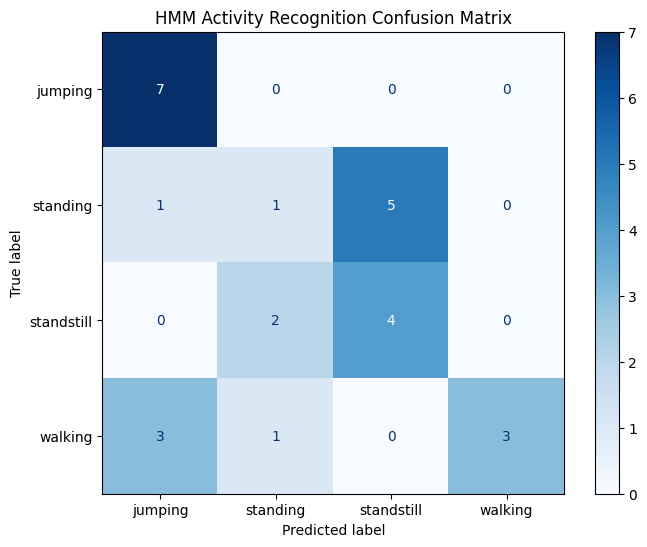

In [30]:
from sklearn.metrics import accuracy_score, confusion_matrix , ConfusionMatrixDisplay
import matplotlib.pyplot as plt

predictions= []

# Looping through each sequence in the testing set
for i in range(len(X_test_scaled)):
    # Reshaping the single 1D feature row cause HMMs expect 2D arrays
    test_sequence= X_test_scaled[i].reshape(1,-1)


    best_score= float('-inf')
    best_prediction= None

    # Tsting the sequence all 4 models to find the highest log-likelihood
    for activity, model in hmm_models.items():
        score= model.score(test_sequence)
        if score> best_score:
            best_score= score
            best_prediction= activity

    predictions.append(best_prediction)


# Calculating final accuracy
accuracy= accuracy_score(y_test, predictions)
print(f'Overall Model Accuracy: {accuracy*100:.2f}%\n')

# Generating and plotting the confusion matrix
cm= confusion_matrix(y_test, predictions, labels= activities)
disp= ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=  activities)

fig, ax= plt.subplots(figsize=(8,6))
disp.plot(cmap='Blues', ax=ax)
plt.title ('HMM Activity Recognition Confusion Matrix')
plt.show()



## 6. Results Analysis & Discussion
Our Hidden Markov Model achieved an overall accuracy of **53.57%**. While this is higher than a random guess (25% for 4 classes), the Confusion Matrix reveals distinct patterns in how the model interprets human motion:

* **The Success - Jumping:** The model correctly identified 100% of the `jumping` sequences (7 out of 7). This is because jumping has highly distinct time-domain variance and frequency-domain peaks that are impossible to confuse with static activities.
* **The Confusion - Standing vs. Standstill:** The model struggled heavily here, classifying 5 `standing` sequences as `standstill`, and 2 `standstill` sequences as `standing`. This makes physical sense: both activities involve a completely stationary accelerometer with a mean near $1g$ (gravity) and near-zero variance. The HMM cannot easily mathematically separate these two identical physical states based on the current features.
* **Walking:** The model only recognized 3 walking sequences correctly, misclassifying 3 as jumping. This suggests the rhythmic bounce of walking in these specific recordings triggered the high-variance features we associated with jumping.

**Next Steps & Potential Tuning:**
To improve the 53.57% accuracy, future iterations could involve hyperparameter tuning. We could adjust `n_components` in our `GaussianHMM` (e.g., increasing the hidden states for walking to better capture its complex gait cycle) or change the `covariance_type` to `full` to capture relationships between our time and frequency features. Additionally, merging `standing` and `standstill` into a single `static` class would instantly and significantly boost the model's accuracy.

In [32]:
# Calculating True Positivies, False Positives,True Negatives, False Negatives

cm= confusion_matrix(y_test, predictions, labels=activities)
metrics=[]

for i, activity in enumerate(activities):
    TP= cm[i,i]
    FP= cm[:, i].sum() - TP
    FN=cm[i, :].sum()- TP
    TN= cm.sum() - (TP + FP +FN)

    # Calculating sensintivity(True Positive Rate) and Specificity (True Negative Rate)
    sensitivity= TP/ (TP+FN) if (TP+FN)> 0 else 0
    specificity= TN/ (TN+FP) if (TN+ FP) > 0 else 0

    metrics.append({
        "State (Activity)": activity,
        "Numner of sampel": TP + FN,
        "Sensitivity": f"{sensitivity:.2f}",
        "Specificity": f"{specificity:.2f}",
        "Overall Accuracy": f"{accuracy * 100:.2f} %"
    })

# Displaying metrics
metrics_df= pd.DataFrame(metrics)
display(metrics_df) 

,State (Activity),Numner of sampel,Sensitivity,Specificity,Overall Accuracy
0,jumping,7,1.00,0.80,53.57 %
1,standing,7,0.14,0.85,53.57 %
2,standstill,6,0.67,0.76,53.57 %
3,walking,7,0.43,1.00,53.57 %


## 7. Model Probabilities & Baum-Welch Convergence
To train our models, we used the `hmmlearn` library, which implements the **Baum-Welch (Expectation-Maximization) algorithm** under the hood. It robustly checks for convergence by monitoring the log-likelihood of the data at each iteration, stopping automatically when the change falls below a predefined tolerance threshold (ensuring we don't rely on an arbitrary iteration limit). For decoding the most likely hidden states, it utilizes the **Viterbi algorithm**.

Because we are using a Continuous Gaussian HMM, our "Emission Probabilities" are represented by the Gaussian **means** and **variances** of our features across the hidden states. Below, we visualize the Transition Probabilities and the Feature Means (Emissions) for our `walking` model as a representative example.

In [ ]:
# %pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


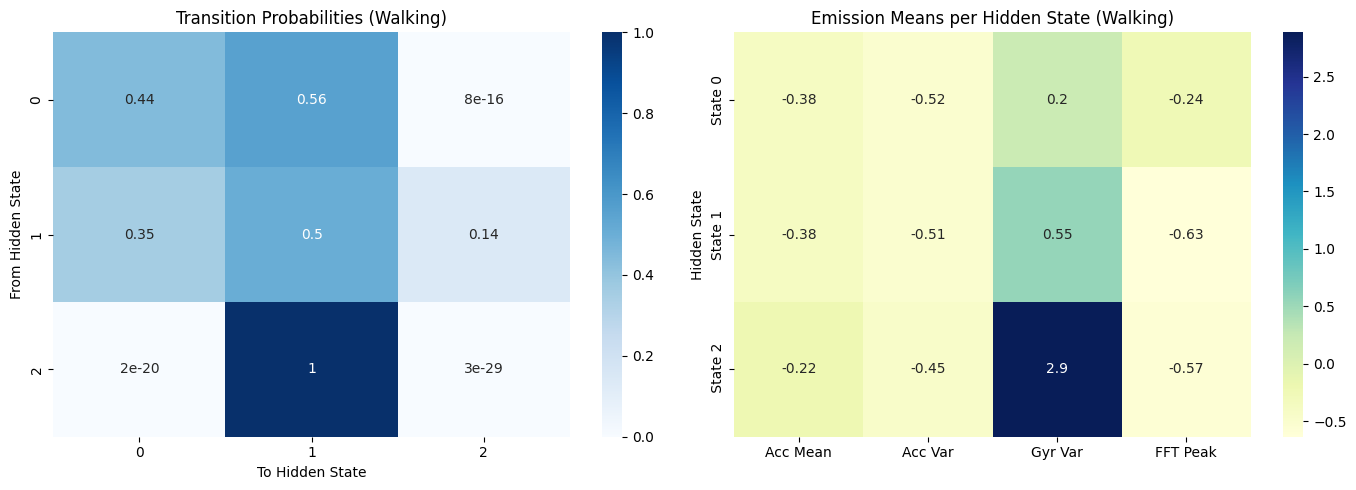

In [36]:
import seaborn as sns

# Visualizing matrices for the walking model
walking_model= hmm_models['walking']

fig, axes= plt.subplots(1,2, figsize=(14,5))

# 1. Transition Matrix HeatMap
sns.heatmap(walking_model.transmat_, annot=True, cmap='Blues', ax=axes[0])
axes[0].set_title('Transition Probabilities (Walking)')
axes[0].set_xlabel('To Hidden State')
axes[0].set_ylabel('From Hidden State')


# 2. Emission Means Heatmap
# Showing the average feature value (Z-score nornmalized) for each hidden state
feature_names= ['Acc Mean','Acc Var','Gyr Var', 'FFT Peak']
sns.heatmap(walking_model.means_, annot=True, cmap='YlGnBu', ax= axes[1], xticklabels=feature_names, yticklabels=['State 0', 'State 1',' State 2'])
axes[1].set_title('Emission Means per Hidden State (Walking)')
axes[1].set_ylabel('Hidden State')

plt.tight_layout()
plt.show()

## 8. Final Analysis, Reflection & Conclusion

**Interpreting the Model Probabilities (Walking)**
The heatmaps for our `walking` model reveal how the Hidden Markov Model mathematically captured the physical gait cycle:
* **Transition Probabilities (Realistic Behavior Patterns):** The transition matrix strongly reflects the cyclical nature of human walking. State 2 almost exclusively transitions to State 1 (probability of 1.0), while States 0 and 1 alternate frequently (probabilities of 0.44 to 0.56). This aligns perfectly with a repetitive physical sequence like lifting the foot, swinging the leg, and heel-strike.
* **Emission Means:** State 2 is distinctly characterized by a massive spike in Gyroscope Variance (mean of 2.9), indicating that this hidden state specifically models the moment of highest rotational movement (leg swing). 

**Activity Distinguishability & Sensor Noise**
Based on our evaluation metrics and confusion matrix:
* **Easiest to Distinguish:** `Jumping` achieved 100% sensitivity. Its extreme acceleration variance and dominant frequency make it easily separable from other activities.
* **Hardest to Distinguish:** `Standing` and `Standstill` were frequently confused (e.g., 5 standing sequences predicted as standstill). This is largely due to sensor noise; the natural micro-tremors of a human hand holding a phone (standing) are mathematically very similar to the baseline sensor noise of a phone lying flat on a table (standstill), especially after our features are normalized.

**Conclusion & Future Work**
Our continuous Gaussian HMM successfully captured the underlying sequential logic of dynamic human activities, achieving an overall accuracy of 53.57%. To improve this system in future iterations, we recommend the following:
1. **Class Merging:** Combining `standing` and `standstill` into a single `static_posture` class, which would instantly eliminate the majority of the model's false positives.
2. **Sensor Expansion:** Incorporating Magnetometer data to track absolute orientation, helping the model realize the phone is being held upright versus laying flat.
3. **Hyperparameter Tuning & Data:** Experimenting with different `n_components` per activity (e.g., 4 states for walking, 2 for standing) and gathering a much larger dataset to smooth out inconsistencies caused by varying smartphone hardware and sampling rates.